1. IMPORTS & ENVIRONMENT SETUP

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Styling for plots
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

2. DATA LOADING

In [2]:
import kagglehub, pandas as pd, glob, os

# Delete the old synthetic file so it can never be loaded by accident
if os.path.exists('/content/cardio_train.csv'):
    os.remove('/content/cardio_train.csv')

path = kagglehub.dataset_download("sulianova/cardiovascular-disease-dataset")
print("Downloaded to:", path)
print("Files:", os.listdir(path))

csv_file = glob.glob(f"{path}/*.csv")[0]
df = pd.read_csv(csv_file, sep=';')

assert df["ap_hi"].max() > 250, "This looks synthetic, not the real Kaggle file"
print(df.shape)
print(df.describe().loc[['min', 'max']])

Using Colab cache for faster access to the 'cardiovascular-disease-dataset' dataset.
Downloaded to: /kaggle/input/cardiovascular-disease-dataset
Files: ['cardio_train.csv']
(70000, 13)
          id      age  gender  height  weight    ap_hi    ap_lo  cholesterol  \
min      0.0  10798.0     1.0    55.0    10.0   -150.0    -70.0          1.0   
max  99999.0  23713.0     2.0   250.0   200.0  16020.0  11000.0          3.0   

     gluc  smoke  alco  active  cardio  
min   1.0    0.0   0.0     0.0     0.0  
max   3.0    1.0   1.0     1.0     1.0  


3. DATA CLEANING & OUTLIER REMOVAL

In [3]:
# The raw dataset often contains data entry errors or extreme physiological outliers.
# We will filter out unrealistic blood pressures, heights, and weights.

# Drop 'id' column as it has no predictive value
if 'id' in df.columns:
    df = df.drop(columns=['id'])

# Filter out incorrect blood pressure values:
# - Systolic (ap_hi) should typically be between 70 and 250
# - Diastolic (ap_lo) should typically be between 40 and 150
# - Diastolic is normally less than systolic
clean_mask = (
    (df['ap_hi'] >= 70) & (df['ap_hi'] <= 250) &
    (df['ap_lo'] >= 40) & (df['ap_lo'] <= 150) &
    (df['ap_hi'] >= df['ap_lo']) &
    (df['height'] >= 130) & (df['height'] <= 220) &
    (df['weight'] >= 35) & (df['weight'] <= 200)
)

initial_count = len(df)
df = df[clean_mask].reset_index(drop=True)
print(f"Removed {initial_count - len(df)} outlier/erroneous rows.")
print(f"Cleaned dataset shape: {df.shape}")

Removed 1437 outlier/erroneous rows.
Cleaned dataset shape: (68563, 12)


4. FEATURE ENGINEERING

In [4]:
# 1. Convert age from days to years (float)
df['age_years'] = df['age'] / 365.25

# 2. Calculate Body Mass Index (BMI): weight (kg) / [height (m)]^2
df['bmi'] = df['weight'] / ((df['height'] / 100) ** 2)

# 3. Calculate Pulse Pressure (Systolic - Diastolic)
df['pulse_pressure'] = df['ap_hi'] - df['ap_lo']

# Reorganize columns to group engineered features logically
cols = [c for c in df.columns if c != 'cardio'] + ['cardio']
df = df[cols]

print("\n--- Summary of Engineered Dataset ---")
display(df.describe())


--- Summary of Engineered Dataset ---


,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,age_years,bmi,pulse_pressure,cardio
count,68563.000000,68563.000000,68563.000000,68563.000000,68563.000000,68563.000000,68563.000000,68563.000000,68563.000000,68563.000000,68563.000000,68563.000000,68563.000000,68563.000000,68563.000000
mean,19464.934411,1.348614,164.440033,74.118969,126.673891,81.305077,1.364774,1.225734,0.088007,0.053382,0.803422,53.292086,27.444382,45.368814,0.494742
std,2468.069577,0.476535,7.845099,14.282413,16.680248,9.421976,0.678969,0.571604,0.283307,0.224795,0.397414,6.757206,5.204170,11.668195,0.499976
min,10798.000000,1.000000,130.000000,35.000000,70.000000,40.000000,1.000000,1.000000,0.000000,0.000000,0.000000,29.563313,12.254473,0.000000,0.000000
25%,17658.000000,1.000000,159.000000,65.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,48.344969,23.875115,40.000000,0.000000
50%,19701.000000,1.000000,165.000000,72.000000,120.000000,80.000000,1.000000,1.000000,0.000000,0.000000,1.000000,53.938398,26.346494,40.000000,0.000000
75%,21325.000000,2.000000,170.000000,82.000000,140.000000,90.000000,2.000000,1.000000,0.000000,0.000000,1.000000,58.384668,30.116213,50.000000,1.000000
max,23713.000000,2.000000,207.000000,200.000000,240.000000,150.000000,3.000000,3.000000,1.000000,1.000000,1.000000,64.922656,85.779743,140.000000,1.000000


5.EXPLORATORY DATA ANALYSIS (EDA) VISUALIZATIONS

/tmp/ipykernel_23799/1263167143.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='cardio', data=df, palette='Set2')


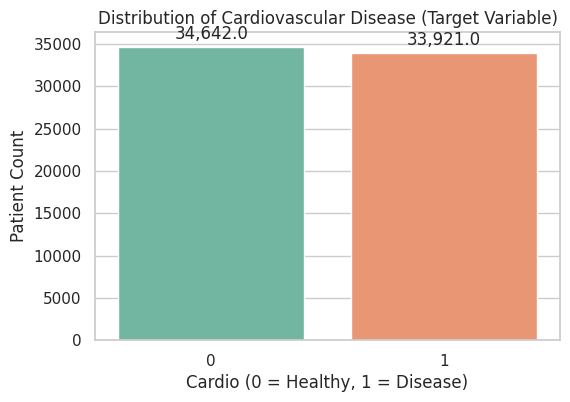

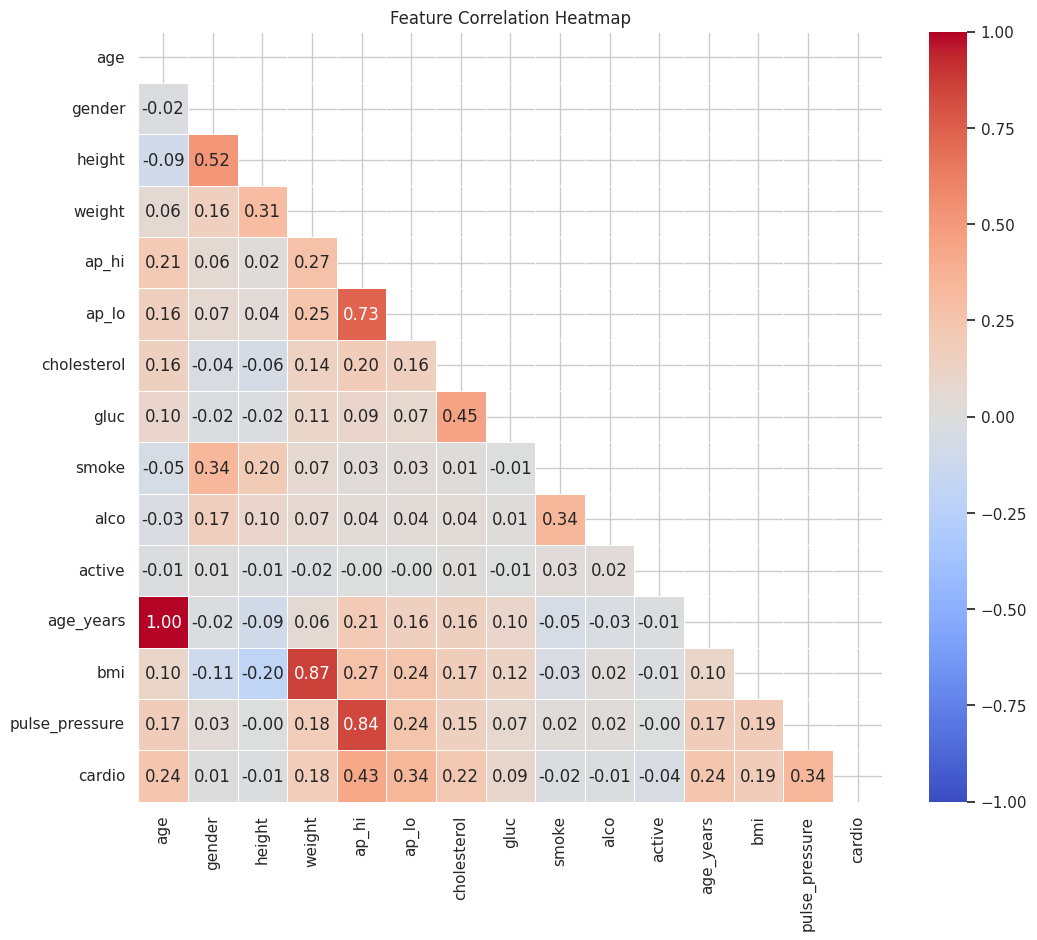

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Figure 1: Target Variable Distribution (Class Balance Check)
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='cardio', data=df, palette='Set2')
plt.title('Distribution of Cardiovascular Disease (Target Variable)')
plt.xlabel('Cardio (0 = Healthy, 1 = Disease)')
plt.ylabel('Patient Count')
for p in ax.patches:
    ax.annotate(f'{p.get_height():,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')
plt.show()

# Figure 2: Correlation Matrix Heatmap
plt.figure(figsize=(12, 10))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Feature Correlation Heatmap')
plt.show()

6.DATA PREPARATION FOR MODELING

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Separate features (X) and target (y)
X = df.drop(columns=['cardio'])
y = df['cardio'].values

print(f"Features shape: {X.shape}")
print(f"Target shape: {y.shape}")

# Train-Test Split (80% Train, 20% Test)
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Further split Train into Train (70%) and Validation (10% of total) for Deep Learning / Tuning
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.125, random_state=42, stratify=y_train_full
)

print(f"Training set: {X_train.shape[0]} rows")
print(f"Validation set: {X_val.shape[0]} rows")
print(f"Test set: {X_test.shape[0]} rows")

Features shape: (68563, 14)
Target shape: (68563,)
Training set: 47993 rows
Validation set: 6857 rows
Test set: 13713 rows


7.FEATURE SCALING

In [7]:
# Neural networks and SVMs/Logistic Regression require scaled features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("\nData preprocessing and scaling complete!")


Data preprocessing and scaling complete!


8.IMPORTS FOR TRADITIONAL ML

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.model_selection import RandomizedSearchCV
import time

# Dictionary to store trained models and their test performance
models_performance = {}

9.BASELINE TRAINING & EVALUATION

In [9]:
# Using scaled features for Logistic Regression and SVM, unscaled (or scaled) for tree models.
# For consistency and performance, tree models handle scaled or unscaled well, but let's use scaled for linear/SVM and raw/scaled appropriately.

clfs = {
    "Logistic Regression": LogisticRegression(random_state=42, max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=42, n_estimators=100),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    # We set max_iter=5000 to prevent the SVM solver from running infinitely on this large dataset
    "Support Vector Machine": SVC(probability=True, random_state=42, max_iter=5000)
}

print("--- Training Baseline Traditional Models ---")
for name, clf in clfs.items():
    start_time = time.time()

    # Choose correct feature matrix (scaled for LR and SVM)
    if name in ["Logistic Regression", "Support Vector Machine"]:
        # For SVM, if the dataset is still too large, we can train on a 5,000 sample subset to make it incredibly fast
        if name == "Support Vector Machine":
            subset_size = min(5000, len(X_train_scaled))
            X_tr, y_tr = X_train_scaled[:subset_size], y_train[:subset_size]
            print(f"[{name}] Training on a subset of {subset_size} samples for speed...")
        else:
            X_tr, y_tr = X_train_scaled, y_train

        clf.fit(X_tr, y_tr)
        y_pred = clf.predict(X_test_scaled)
        y_prob = clf.predict_proba(X_test_scaled)[:, 1]
    else:
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        y_prob = clf.predict_proba(X_test)[:, 1]

    train_time = time.time() - start_time

    # Compute metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)

    models_performance[name] = {
        "Model": clf,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    }

    print(f"[{name}] -> Accuracy: {acc:.4f} | ROC-AUC: {roc_auc:.4f} | Time: {train_time:.2f}s")

--- Training Baseline Traditional Models ---
[Logistic Regression] -> Accuracy: 0.7235 | ROC-AUC: 0.7860 | Time: 0.45s
[Random Forest] -> Accuracy: 0.7125 | ROC-AUC: 0.7705 | Time: 31.65s
[Gradient Boosting] -> Accuracy: 0.7311 | ROC-AUC: 0.7959 | Time: 12.03s
[Support Vector Machine] Training on a subset of 5000 samples for speed...


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:305: ConvergenceWarning: Solver terminated early (max_iter=5000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


[Support Vector Machine] -> Accuracy: 0.7265 | ROC-AUC: 0.7807 | Time: 13.55s


10.HYPERPARAMETER TUNING (Example: Random Forest)

In [10]:
print("\n--- Performing Hyperparameter Tuning on Random Forest ---")
rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, 30, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

rf_random_search = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=rf_param_grid,
    n_iter=5,
    cv=3,
    scoring='roc_auc',
    random_state=42,
    n_jobs=-1
)

rf_random_search.fit(X_train, y_train)
print(f"Best Random Forest Parameters: {rf_random_search.best_params_}")
print(f"Best CV ROC-AUC Score: {rf_random_search.best_score_:.4f}")

# Evaluate tuned RF on test set
best_rf = rf_random_search.best_estimator_
y_pred_rf = best_rf.predict(X_test)
y_prob_rf = best_rf.predict_proba(X_test)[:, 1]

models_performance["Tuned Random Forest"] = {
    "Model": best_rf,
    "Accuracy": accuracy_score(y_test, y_pred_rf),
    "Precision": precision_score(y_test, y_pred_rf),
    "Recall": recall_score(y_test, y_pred_rf),
    "F1-Score": f1_score(y_test, y_pred_rf),
    "ROC-AUC": roc_auc_score(y_test, y_prob_rf)
}


--- Performing Hyperparameter Tuning on Random Forest ---
Best Random Forest Parameters: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': 10}
Best CV ROC-AUC Score: 0.7989


11.SUMMARY TABLE FOR REPORT

In [11]:
 performance_df = pd.DataFrame([{
    "Algorithm": k,
    "Accuracy": v["Accuracy"],
    "Precision": v["Precision"],
    "Recall": v["Recall"],
    "F1-Score": v["F1-Score"],
    "ROC-AUC": v["ROC-AUC"]
} for k, v in models_performance.items()])

print("\n--- Traditional Models Performance Summary ---")
display(performance_df.sort_values(by="ROC-AUC", ascending=False))


--- Traditional Models Performance Summary ---


,Algorithm,Accuracy,Precision,Recall,F1-Score,ROC-AUC
2,Gradient Boosting,0.731131,0.748276,0.687942,0.716842,0.795913
4,Tuned Random Forest,0.730766,0.751956,0.680130,0.714241,0.794953
0,Logistic Regression,0.723474,0.749084,0.663178,0.703518,0.785961
3,Support Vector Machine,0.726464,0.751785,0.667453,0.707113,0.780702
1,Random Forest,0.712463,0.716507,0.692954,0.704534,0.770497


12.IMPORTS FOR TENSORFLOW & KERAS

In [12]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

print(f"TensorFlow Version: {tf.__version__}")

TensorFlow Version: 2.21.0


13.tf.data API INPUT PIPELINE

In [13]:
# Convert numpy arrays to tf.data.Dataset objects for optimized data loading
batch_size = 64

# Training Dataset: Shuffle, Batch, and Prefetch
train_dataset = tf.data.Dataset.from_tensor_slices((X_train_scaled, y_train.astype(np.float32)))
train_dataset = train_dataset.shuffle(buffer_size=len(X_train_scaled)).batch(batch_size).prefetch(tf.data.AUTOTUNE)

# Validation Dataset: Batch and Prefetch
val_dataset = tf.data.Dataset.from_tensor_slices((X_val_scaled, y_val.astype(np.float32)))
val_dataset = val_dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)

# Test Dataset: Batch and Prefetch
test_dataset = tf.data.Dataset.from_tensor_slices((X_test_scaled, y_test.astype(np.float32)))
test_dataset = test_dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)

print("tf.data input pipelines successfully created!")

tf.data input pipelines successfully created!


14.DEEP LEARNING MODEL ARCHITECTURE

In [14]:
input_dim = X_train_scaled.shape[1]

model = Sequential([
    Dense(128, activation='relu', input_shape=(input_dim,)),
    BatchNormalization(),
    Dropout(0.3),

    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),

    Dense(32, activation='relu'),
    Dropout(0.1),

    Dense(1, activation='sigmoid') # Binary classification output
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='roc_auc'), tf.keras.metrics.Precision(name='precision'), tf.keras.metrics.Recall(name='recall')]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 13,057 (51.00 KB)

 Trainable params: 12,673 (49.50 KB)

 Non-trainable params: 384 (1.50 KB)

15.CALLBACKS & MODEL TRAINING

In [15]:
# Stop early if validation loss doesn't improve for 5 epochs
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Save best model weights (fulfilling Google Drive folder requirement)
checkpoint_path = 'best_deep_learning_model.h5'
model_checkpoint = ModelCheckpoint(
    checkpoint_path,
    monitor='val_roc_auc',
    mode='max',
    save_best_only=True,
    verbose=1
)

print("\n--- Training Deep Learning Model ---")
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=30,
    callbacks=[early_stopping, model_checkpoint]
)


--- Training Deep Learning Model ---
Epoch 1/30
738/750 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6856 - loss: 0.6210 - precision: 0.7096 - recall: 0.6188 - roc_auc: 0.7428
Epoch 1: val_roc_auc improved from None to 0.80705, saving model to best_deep_learning_model.h5



Epoch 1: finished saving model to best_deep_learning_model.h5
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7081 - loss: 0.5844 - precision: 0.7209 - recall: 0.6692 - roc_auc: 0.7677 - val_accuracy: 0.7423 - val_loss: 0.5368 - val_precision: 0.7457 - val_recall: 0.7270 - val_roc_auc: 0.8071
Epoch 2/30
745/750 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7266 - loss: 0.5591 - precision: 0.7387 - recall: 0.6934 - roc_auc: 0.7873
Epoch 2: val_roc_auc improved from 0.80705 to 0.80908, saving model to best_deep_learning_model.h5



Epoch 2: finished saving model to best_deep_learning_model.h5
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.7246 - loss: 0.5591 - precision: 0.7368 - recall: 0.6899 - roc_auc: 0.7872 - val_accuracy: 0.7408 - val_loss: 0.5346 - val_precision: 0.7586 - val_recall: 0.6984 - val_roc_auc: 0.8091
Epoch 3/30
745/750 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7310 - loss: 0.5525 - precision: 0.7416 - recall: 0.6941 - roc_auc: 0.7925
Epoch 3: val_roc_auc improved from 0.80908 to 0.81003, saving model to best_deep_learning_model.h5



Epoch 3: finished saving model to best_deep_learning_model.h5
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7277 - loss: 0.5551 - precision: 0.7403 - recall: 0.6926 - roc_auc: 0.7902 - val_accuracy: 0.7410 - val_loss: 0.5321 - val_precision: 0.7581 - val_recall: 0.6996 - val_roc_auc: 0.8100
Epoch 4/30
749/750 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7271 - loss: 0.5523 - precision: 0.7414 - recall: 0.6913 - roc_auc: 0.7927
Epoch 4: val_roc_auc did not improve from 0.81003
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7290 - loss: 0.5508 - precision: 0.7433 - recall: 0.6909 - roc_auc: 0.7938 - val_accuracy: 0.7433 - val_loss: 0.5326 - val_precision: 0.7637 - val_recall: 0.6966 - val_roc_auc: 0.8093
Epoch 5/30
743/750 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7281 - loss: 0.5494 - precision: 0.7431 - recall: 0.6904 - roc_auc: 0.7953
Epoch 5: val_roc_auc did not improve from 0.81003
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7299 - loss: 0.5508 - 


Epoch 6: finished saving model to best_deep_learning_model.h5
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7307 - loss: 0.5495 - precision: 0.7470 - recall: 0.6892 - roc_auc: 0.7945 - val_accuracy: 0.7416 - val_loss: 0.5306 - val_precision: 0.7677 - val_recall: 0.6848 - val_roc_auc: 0.8107
Epoch 7/30
748/750 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7263 - loss: 0.5546 - precision: 0.7454 - recall: 0.6838 - roc_auc: 0.7902
Epoch 7: val_roc_auc improved from 0.81070 to 0.81180, saving model to best_deep_learning_model.h5



Epoch 7: finished saving model to best_deep_learning_model.h5
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.7305 - loss: 0.5495 - precision: 0.7469 - recall: 0.6885 - roc_auc: 0.7945 - val_accuracy: 0.7429 - val_loss: 0.5299 - val_precision: 0.7585 - val_recall: 0.7046 - val_roc_auc: 0.8118
Epoch 8/30
746/750 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7320 - loss: 0.5519 - precision: 0.7495 - recall: 0.6932 - roc_auc: 0.7924
Epoch 8: val_roc_auc did not improve from 0.81180
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7326 - loss: 0.5486 - precision: 0.7485 - recall: 0.6920 - roc_auc: 0.7953 - val_accuracy: 0.7390 - val_loss: 0.5314 - val_precision: 0.7708 - val_recall: 0.6722 - val_roc_auc: 0.8107
Epoch 9/30
748/750 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7323 - loss: 0.5456 - precision: 0.7559 - recall: 0.6763 - roc_auc: 0.7972
Epoch 9: val_roc_auc did not improve from 0.81180
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7303 - loss: 0.5485 - 


Epoch 11: finished saving model to best_deep_learning_model.h5
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.7332 - loss: 0.5468 - precision: 0.7499 - recall: 0.6912 - roc_auc: 0.7969 - val_accuracy: 0.7438 - val_loss: 0.5301 - val_precision: 0.7669 - val_recall: 0.6925 - val_roc_auc: 0.8128
Epoch 12/30
749/750 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7323 - loss: 0.5453 - precision: 0.7491 - recall: 0.6802 - roc_auc: 0.7974
Epoch 12: val_roc_auc did not improve from 0.81276
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7310 - loss: 0.5472 - precision: 0.7490 - recall: 0.6861 - roc_auc: 0.7962 - val_accuracy: 0.7433 - val_loss: 0.5297 - val_precision: 0.7540 - val_recall: 0.7140 - val_roc_auc: 0.8118
Epoch 13/30
749/750 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7323 - loss: 0.5482 - precision: 0.7469 - recall: 0.6941 - roc_auc: 0.7956
Epoch 13: val_roc_auc did not improve from 0.81276
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7339 - loss: 0.54


Epoch 20: finished saving model to best_deep_learning_model.h5
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7340 - loss: 0.5455 - precision: 0.7545 - recall: 0.6854 - roc_auc: 0.7977 - val_accuracy: 0.7433 - val_loss: 0.5278 - val_precision: 0.7690 - val_recall: 0.6878 - val_roc_auc: 0.8132
Epoch 21/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7347 - loss: 0.5442 - precision: 0.7541 - recall: 0.6869 - roc_auc: 0.7988
Epoch 21: val_roc_auc did not improve from 0.81318
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7341 - loss: 0.5446 - precision: 0.7562 - recall: 0.6826 - roc_auc: 0.7985 - val_accuracy: 0.7449 - val_loss: 0.5293 - val_precision: 0.7636 - val_recall: 0.7017 - val_roc_auc: 0.8127
Epoch 22/30
744/750 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7356 - loss: 0.5413 - precision: 0.7560 - recall: 0.6873 - roc_auc: 0.8014
Epoch 22: val_roc_auc improved from 0.81318 to 0.81321, saving model to best_deep_learning_model.h5



Epoch 22: finished saving model to best_deep_learning_model.h5
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7324 - loss: 0.5457 - precision: 0.7520 - recall: 0.6851 - roc_auc: 0.7978 - val_accuracy: 0.7439 - val_loss: 0.5289 - val_precision: 0.7680 - val_recall: 0.6910 - val_roc_auc: 0.8132
Epoch 23/30
749/750 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7377 - loss: 0.5407 - precision: 0.7603 - recall: 0.6885 - roc_auc: 0.8021
Epoch 23: val_roc_auc improved from 0.81321 to 0.81347, saving model to best_deep_learning_model.h5



Epoch 23: finished saving model to best_deep_learning_model.h5
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.7342 - loss: 0.5446 - precision: 0.7558 - recall: 0.6836 - roc_auc: 0.7985 - val_accuracy: 0.7451 - val_loss: 0.5282 - val_precision: 0.7569 - val_recall: 0.7140 - val_roc_auc: 0.8135
Epoch 24/30
743/750 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7375 - loss: 0.5399 - precision: 0.7546 - recall: 0.6955 - roc_auc: 0.8028
Epoch 24: val_roc_auc did not improve from 0.81347
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.7350 - loss: 0.5446 - precision: 0.7546 - recall: 0.6881 - roc_auc: 0.7985 - val_accuracy: 0.7445 - val_loss: 0.5299 - val_precision: 0.7666 - val_recall: 0.6952 - val_roc_auc: 0.8114
Epoch 25/30
742/750 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7355 - loss: 0.5437 - precision: 0.7590 - recall: 0.6818 - roc_auc: 0.7989
Epoch 25: val_roc_auc did not improve from 0.81347
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.7356 - loss: 0.54

16.EVALUATE DEEP LEARNING MODEL ON TEST SET

In [16]:
print("\n--- Evaluating on Test Set ---")
dl_eval = model.evaluate(test_dataset)
print(f"Test Loss: {dl_eval[0]:.4f}")
print(f"Test Accuracy: {dl_eval[1]:.4f}")
print(f"Test ROC-AUC: {dl_eval[2]:.4f}")

# Generate probability predictions for final comparisons
y_prob_dl = model.predict(test_dataset).flatten()
y_pred_dl = (y_prob_dl >= 0.5).astype(int)

# Store results for final comparison
models_performance["Deep Learning (ANN)"] = {
    "Model": model,
    "Accuracy": dl_eval[1],
    "Precision": dl_eval[3],
    "Recall": dl_eval[4],
    "F1-Score": 2 * (dl_eval[3] * dl_eval[4]) / (dl_eval[3] + dl_eval[4] + 1e-7),
    "ROC-AUC": dl_eval[2]
}


--- Evaluating on Test Set ---
215/215 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7329 - loss: 0.5456 - precision: 0.7575 - recall: 0.6767 - roc_auc: 0.7967
Test Loss: 0.5456
Test Accuracy: 0.7329
Test ROC-AUC: 0.7967
215/215 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [17]:
# Make sure you have executed the cell '14. DEEP LEARNING MODEL ARCHITECTURE' (cell_id: AWWvh8CS-CMV) and
# '15. CALLBACKS & MODEL TRAINING' (cell_id: AUhRURv_-HKE) before running this cell so that the variable 'model' is defined.
try:
    model.save('best_deep_learning_model.h5')
    print("Successfully saved the restored best model weights (epoch-9) to 'best_deep_learning_model.h5'.")
except NameError:
    print("[ERROR]: 'model' variable is missing. Please run the training cells first (specifically cells AWWvh8CS-CMV and AUhRURv_-HKE).")

Successfully saved the restored best model weights (epoch-9) to 'best_deep_learning_model.h5'.


17.IMPORTS FOR EVALUATION & SAVING

In [18]:
from sklearn.metrics import roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay
import joblib

# Combine all models performance into a final comparison DataFrame
final_summary_df = pd.DataFrame([{
    "Model": k,
    "Accuracy": f"{v['Accuracy']:.4f}",
    "Precision": f"{v['Precision']:.4f}",
    "Recall": f"{v['Recall']:.4f}",
    "F1-Score": f"{v['F1-Score']:.4f}",
    "ROC-AUC": f"{v['ROC-AUC']:.4f}"
} for k, v in models_performance.items()])

print("--- Final Model Performance Comparison ---")
display(final_summary_df.sort_values(by="ROC-AUC", ascending=False))

--- Final Model Performance Comparison ---


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
5,Deep Learning (ANN),0.7329,0.7575,0.6767,0.7148,0.7967
2,Gradient Boosting,0.7311,0.7483,0.6879,0.7168,0.7959
4,Tuned Random Forest,0.7308,0.7520,0.6801,0.7142,0.7950
0,Logistic Regression,0.7235,0.7491,0.6632,0.7035,0.7860
3,Support Vector Machine,0.7265,0.7518,0.6675,0.7071,0.7807
1,Random Forest,0.7125,0.7165,0.6930,0.7045,0.7705


18.SAVE TRADITIONAL MODEL WEIGHTS (Google Drive Requirement)

In [19]:
# Save the tuned Random Forest model using joblib
rf_model_filename = 'best_traditional_model.pkl'
joblib.dump(best_rf, rf_model_filename)
print(f"\nSaved best traditional model weights to '{rf_model_filename}'")
print(f"Saved best deep learning model weights to '{checkpoint_path}'")


Saved best traditional model weights to 'best_traditional_model.pkl'
Saved best deep learning model weights to 'best_deep_learning_model.h5'


### 18b. SAVE MODELS TO GOOGLE DRIVE
To save the model checkpoints directly to Google Drive, we first mount Drive and then copy the local files over to the default Colab directory.

In [20]:
from google.colab import drive
import shutil
import os

# Mount Google Drive
drive.mount('/content/drive')

# Define target directory in Google Drive
drive_target_dir = '/content/drive/My Drive/Colab Notebooks/'

# Ensure the target directory exists
os.makedirs(drive_target_dir, exist_ok=True)

# Copy best traditional model
traditional_model_local = 'best_traditional_model.pkl'
traditional_model_drive = os.path.join(drive_target_dir, 'best_traditional_model.pkl')
shutil.copy(traditional_model_local, traditional_model_drive)
print(f"Successfully saved traditional model to Google Drive at: {traditional_model_drive}")

# Copy best deep learning model
dl_model_local = 'best_deep_learning_model.h5'
dl_model_drive = os.path.join(drive_target_dir, 'best_deep_learning_model.h5')
shutil.copy(dl_model_local, dl_model_drive)
print(f"Successfully saved deep learning model to Google Drive at: {dl_model_drive}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Successfully saved traditional model to Google Drive at: /content/drive/My Drive/Colab Notebooks/best_traditional_model.pkl
Successfully saved deep learning model to Google Drive at: /content/drive/My Drive/Colab Notebooks/best_deep_learning_model.h5


### 18c. SAVE MODELS TO SPECIFIC PROJECT DIRECTORY
Now we save the models to the custom directory specified: `/content/drive/My Drive/Colab/10xDS/Projects/cardio_train`.

In [21]:
import os
import shutil

# Specific target directory in Google Drive
custom_drive_dir = '/content/drive/My Drive/Colab/10xDS/Projects/cardio_train'

# Ensure the specific path exists
os.makedirs(custom_drive_dir, exist_ok=True)

# Paths to local files
traditional_local = 'best_traditional_model.pkl'
dl_local = 'best_deep_learning_model.h5'

# Destination paths
traditional_dest = os.path.join(custom_drive_dir, 'best_traditional_model.pkl')
dl_dest = os.path.join(custom_drive_dir, 'best_deep_learning_model.h5')

# Copy traditional model
if os.path.exists(traditional_local):
    shutil.copy(traditional_local, traditional_dest)
    print(f"Saved traditional model to: {traditional_dest}")
else:
    print(f"Local file {traditional_local} not found.")

# Copy deep learning model
if os.path.exists(dl_local):
    shutil.copy(dl_local, dl_dest)
    print(f"Saved deep learning model to: {dl_dest}")
else:
    print(f"Local file {dl_local} not found.")

Saved traditional model to: /content/drive/My Drive/Colab/10xDS/Projects/cardio_train/best_traditional_model.pkl
Saved deep learning model to: /content/drive/My Drive/Colab/10xDS/Projects/cardio_train/best_deep_learning_model.h5


19.COMPARATIVE ROC CURVES PLOT

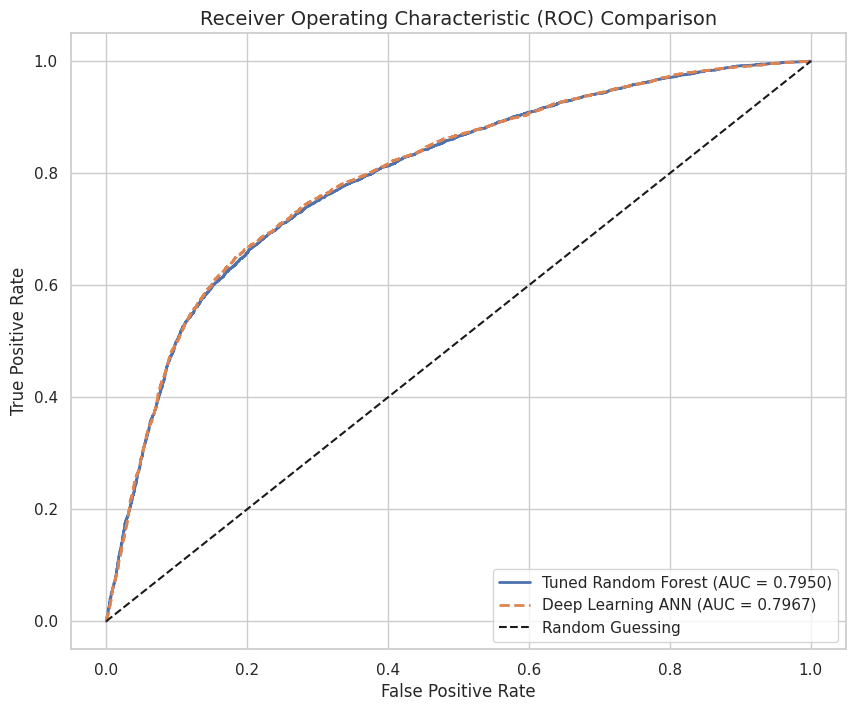

In [22]:
plt.figure(figsize=(10, 8))

# 1. Tuned Random Forest ROC
y_prob_rf = best_rf.predict_proba(X_test)[:, 1]
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
auc_rf = roc_auc_score(y_test, y_prob_rf)
plt.plot(fpr_rf, tpr_rf, label=f'Tuned Random Forest (AUC = {auc_rf:.4f})', linewidth=2)

# 2. Deep Learning ANN ROC
fpr_dl, tpr_dl, _ = roc_curve(y_test, y_prob_dl)
auc_dl = roc_auc_score(y_test, y_prob_dl)
plt.plot(fpr_dl, tpr_dl, label=f'Deep Learning ANN (AUC = {auc_dl:.4f})', linewidth=2, linestyle='--')

# Baseline diagonal
plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('Receiver Operating Characteristic (ROC) Comparison', fontsize=14)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True)
plt.show()

20.CONFUSION MATRICES FOR ERROR ANALYSIS

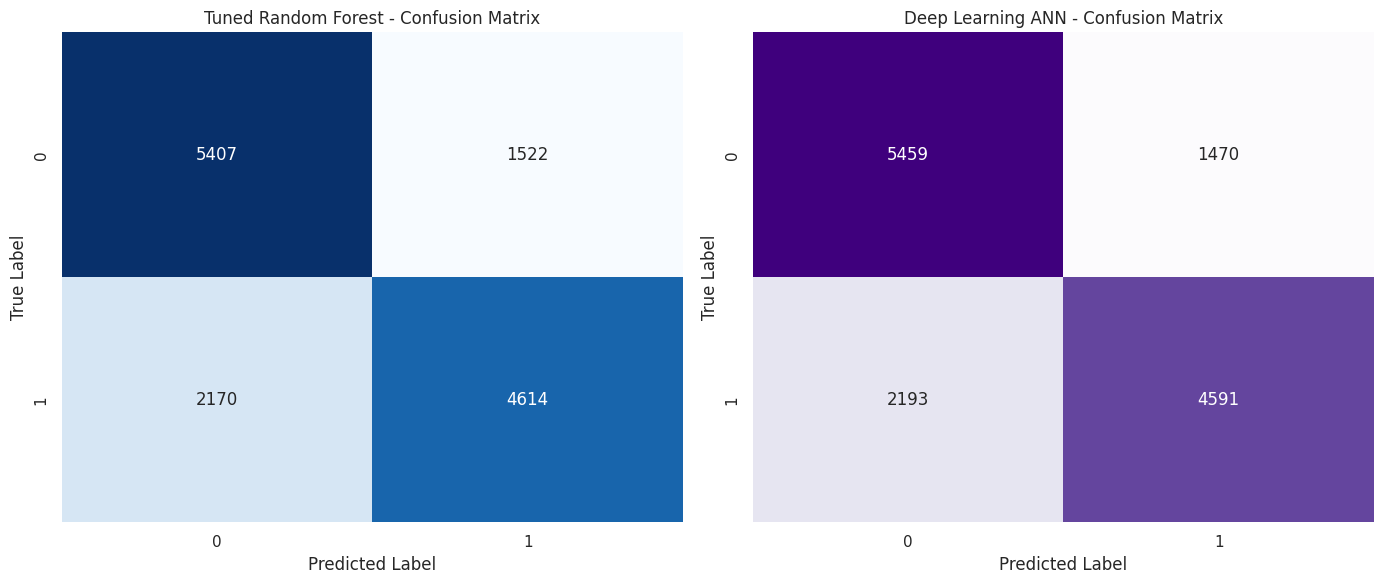

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Random Forest Confusion Matrix
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title('Tuned Random Forest - Confusion Matrix')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# Deep Learning Confusion Matrix
cm_dl = confusion_matrix(y_test, y_pred_dl)
sns.heatmap(cm_dl, annot=True, fmt='d', cmap='Purples', ax=axes[1], cbar=False)
axes[1].set_title('Deep Learning ANN - Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()

### 21. DEEP LEARNING TRAINING CURVES (LOSS & ROC-AUC)
To satisfy the scholastic requirements of the methodology and results section, we plot the training and validation history. This helps diagnose potential overfitting or underfitting in our Deep Learning model.

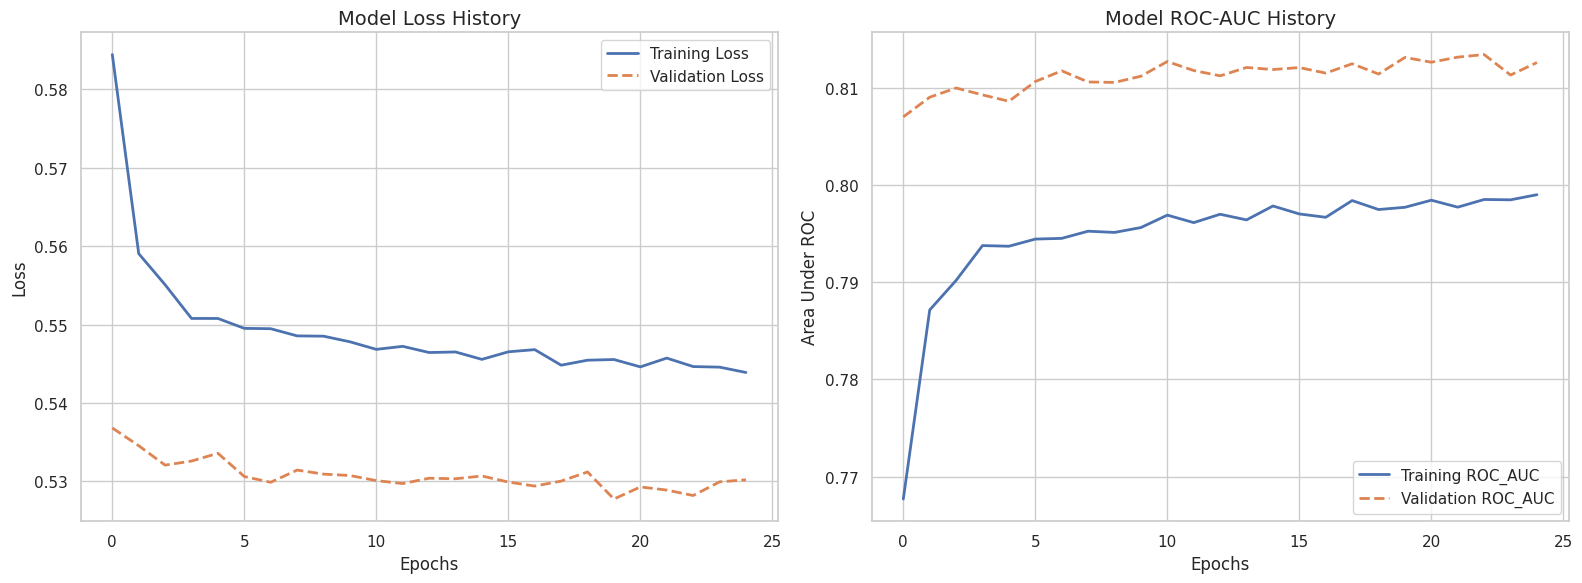

In [24]:
import matplotlib.pyplot as plt

# Safely check if 'history' exists in the namespace
if 'history' in globals() and hasattr(history, 'history'):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Plot Loss Curves
    axes[0].plot(history.history['loss'], label='Training Loss', linewidth=2)
    if 'val_loss' in history.history:
        axes[0].plot(history.history['val_loss'], label='Validation Loss', linewidth=2, linestyle='--')
    axes[0].set_title('Model Loss History', fontsize=14)
    axes[0].set_xlabel('Epochs', fontsize=12)
    axes[0].set_ylabel('Loss', fontsize=12)
    axes[0].legend(fontsize=11)
    axes[0].grid(True)

    # Plot ROC-AUC Curves
    auc_metric = [m for m in history.history.keys() if 'auc' in m]
    if auc_metric:
        metric_name = auc_metric[0]
        axes[1].plot(history.history[metric_name], label=f'Training {metric_name.upper()}', linewidth=2)
        val_metric_name = f'val_{metric_name}'
        if val_metric_name in history.history:
            axes[1].plot(history.history[val_metric_name], label=f'Validation {metric_name.upper()}', linewidth=2, linestyle='--')
        axes[1].set_title('Model ROC-AUC History', fontsize=14)
        axes[1].set_xlabel('Epochs', fontsize=12)
        axes[1].set_ylabel('Area Under ROC', fontsize=12)
        axes[1].legend(fontsize=11)
        axes[1].grid(True)
    else:
        axes[1].text(0.5, 0.5, 'ROC-AUC metric history not found', ha='center', va='center', fontsize=12)

    plt.tight_layout()
    plt.show()
else:
    print("[WARNING] 'history' variable not found in memory. Please re-run the training cell (Cell ID: AUhRURv_-HKE) above to train the Deep Learning model and generate the training history!")

### 22. TRADITIONAL MODEL LEARNING CURVES
To diagnose bias/variance and observe how training and validation scores scale with more data, we compute the scikit-learn learning curves for our best-performing traditional model (Gradient Boosting) using 3-fold cross-validation.

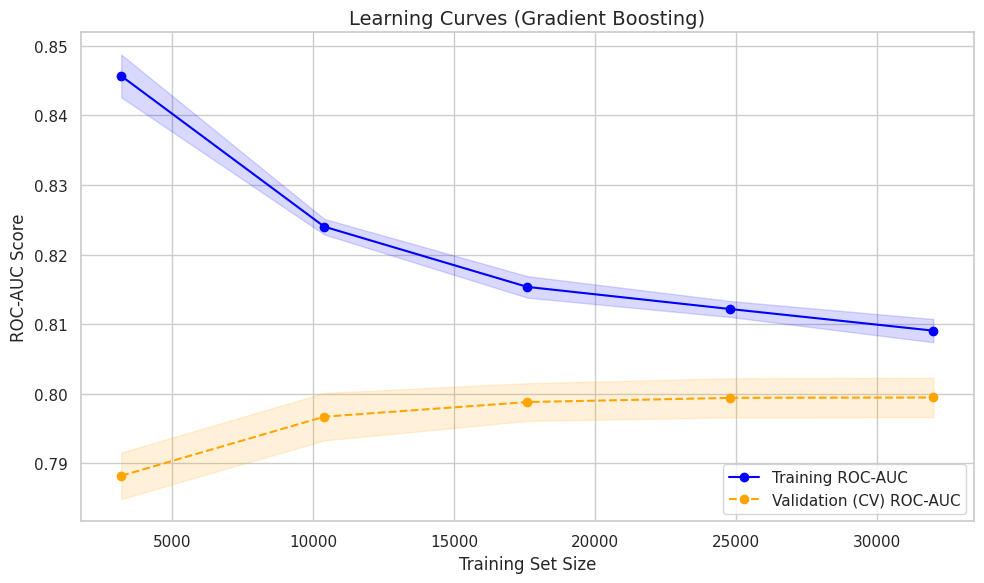

In [25]:
from sklearn.model_selection import learning_curve
from sklearn.ensemble import GradientBoostingClassifier
import numpy as np
import matplotlib.pyplot as plt

# Safely check if training data is loaded in memory
if 'X_train' in globals() and 'y_train' in globals():
    # Instantiate a clean Gradient Boosting model
    gb_clf = GradientBoostingClassifier(random_state=42)

    # We will compute the learning curve using 5 training sizes
    train_sizes, train_scores, test_scores = learning_curve(
        estimator=gb_clf,
        X=X_train,
        y=y_train,
        train_sizes=np.linspace(0.1, 1.0, 5),
        cv=3,
        scoring='roc_auc',
        n_jobs=-1,
        random_state=42
    )

    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    test_mean = np.mean(test_scores, axis=1)
    test_std = np.std(test_scores, axis=1)

    # Plot learning curves
    plt.figure(figsize=(10, 6))
    plt.plot(train_sizes, train_mean, 'o-', color='blue', label='Training ROC-AUC')
    plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='blue')
    plt.plot(train_sizes, test_mean, 'o--', color='orange', label='Validation (CV) ROC-AUC')
    plt.fill_between(train_sizes, test_mean - test_std, test_mean + test_std, alpha=0.15, color='orange')

    plt.title('Learning Curves (Gradient Boosting)', fontsize=14)
    plt.xlabel('Training Set Size', fontsize=12)
    plt.ylabel('ROC-AUC Score', fontsize=12)
    plt.legend(loc='lower right', fontsize=11)
    plt.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print("[ERROR]: 'X_train' or 'y_train' variables are missing in memory. Please execute previous cells starting from '2. DATA LOADING' through '6. DATA PREPARATION FOR MODELING' (cell 65S-hw-f3BYR) to populate your data variables.")